# Montessori Schools Worldwide: Counts by Country, Region and City

Starter notebook for the open dataset from [Montessori School Finder](https://www.montessorischoolfinder.com/). The files hold aggregate counts only. Every row has a `msf_url` that opens the matching place page on Montessori School Finder.

Read the counts as a directory snapshot, not as a census.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

BASE = '../data'  # or 'https://raw.githubusercontent.com/montessoritheory/montessori-schools-worldwide-counts/main/data'
country = pd.read_csv(f'{BASE}/by_country.csv')
region = pd.read_csv(f'{BASE}/by_region.csv')
city = pd.read_csv(f'{BASE}/by_city.csv')
programs = pd.read_csv(f'{BASE}/programs_by_country.csv')
print('Directory snapshot:', country.directory_date.iloc[0])
country.head()

Directory snapshot: 2026-11-17


,country_code,iso2,country,schools,share_of_directory_pct,cities_with_schools,regions_with_schools,verified_schools,verified_share_pct,msf_url,directory_date
0,US,US,United States,5643,41.06,2555,51,4431.0,78.5,https://www.montessorischoolfinder.com/locatio...,2026-11-17
1,IN,IN,India,1590,11.57,570,30,307.0,19.3,https://www.montessorischoolfinder.com/locatio...,2026-11-17
2,DE,DE,Germany,826,6.01,428,16,591.0,71.5,https://www.montessorischoolfinder.com/locatio...,2026-11-17
3,IE,IE,Ireland,750,5.46,236,26,201.0,26.8,https://www.montessorischoolfinder.com/locatio...,2026-11-17
4,GB-ENG,GB,England,703,5.12,288,9,516.0,73.4,https://www.montessorischoolfinder.com/locatio...,2026-11-17


## Do the Levels Add Up?

Cities add up to regions add up to countries add up to the directory total.

In [2]:
print(country.schools.sum(), region.schools.sum(), city.schools.sum())
assert country.schools.sum() == region.schools.sum() == city.schools.sum()

13742 13742 13742


## Where Are the Listed Schools?

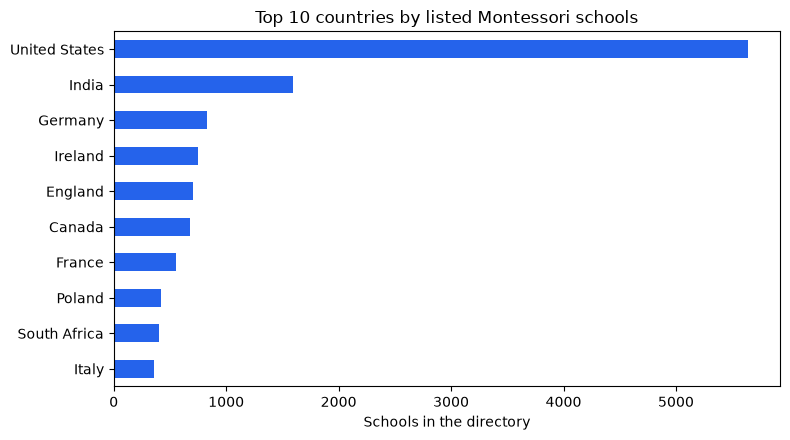

Top 5 countries hold 69% of the directory


In [3]:
top = country.sort_values('schools', ascending=False).head(10)
ax = top.set_index('country').schools.iloc[::-1].plot.barh(color='#2563eb', figsize=(8, 4.5))
ax.set_xlabel('Schools in the directory'); ax.set_ylabel('')
ax.set_title('Top 10 countries by listed Montessori schools')
plt.tight_layout(); plt.show()
print(f'Top 5 countries hold {country.schools.head(5).sum() / country.schools.sum():.0%} of the directory')

## How Concentrated Are Cities?

In [4]:
print('Cities with a page:', len(city))
print('Cities with a single school:', (city.schools == 1).sum(), f'({(city.schools == 1).mean():.0%})')
print('Cities with 10 or more schools:', (city.schools >= 10).sum())
city.sort_values('schools', ascending=False).head(10)[['city', 'country', 'schools', 'msf_url']]

Cities with a page: 6018
Cities with a single school: 3841 (64%)
Cities with 10 or more schools: 152


,city,country,schools,msf_url
593,London,England,242,https://www.montessorischoolfinder.com/locatio...
2080,Lucknow,India,101,https://www.montessorischoolfinder.com/locatio...
364,Calgary,Canada,92,https://www.montessorischoolfinder.com/locatio...
5520,Houston,United States,76,https://www.montessorischoolfinder.com/locatio...
2171,Kolkata,India,74,https://www.montessorischoolfinder.com/locatio...
5031,New York,United States,70,https://www.montessorischoolfinder.com/locatio...
3120,Cape Town,South Africa,68,https://www.montessorischoolfinder.com/locatio...
2918,Warsaw,Poland,64,https://www.montessorischoolfinder.com/locatio...
3530,Los Angeles,United States,60,https://www.montessorischoolfinder.com/locatio...
953,Paris,France,58,https://www.montessorischoolfinder.com/locatio...


## Verified Share by Country

A school is counted as verified when an official record or the school's own website confirms it is Montessori. The share is left blank for countries with fewer than 10 schools.

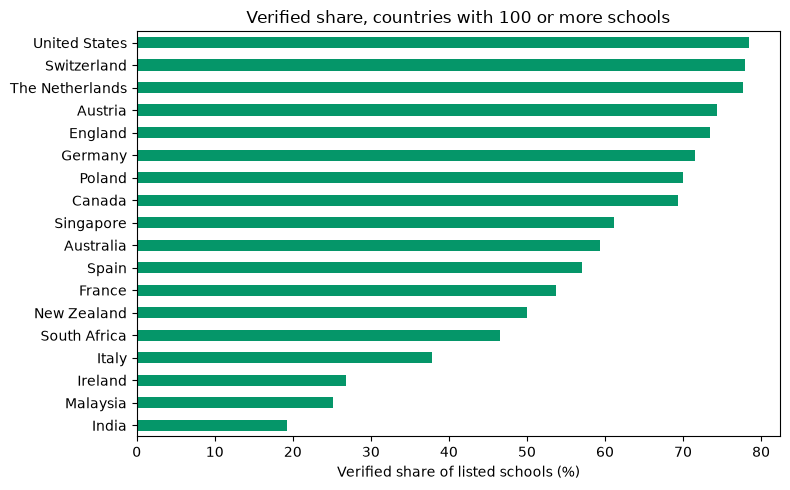

In [5]:
v = country.dropna(subset=['verified_share_pct']).query('schools >= 100').sort_values('verified_share_pct')
ax = v.set_index('country').verified_share_pct.plot.barh(color='#059669', figsize=(8, 5))
ax.set_xlabel('Verified share of listed schools (%)'); ax.set_ylabel('')
ax.set_title('Verified share, countries with 100 or more schools')
plt.tight_layout(); plt.show()

## Programs by Country

One school can list several programs, so program columns do not add up to `schools`.

In [6]:
cols = ['infant', 'toddler', 'daycare', 'preschool', 'kindergarten', 'elementary', 'middle_school', 'high_school', 'no_program_listed']
world = programs[programs.country_code == 'ALL'].iloc[0]
(world[cols] / world.schools * 100).round(1).sort_values(ascending=False)

preschool            49.8
no_program_listed    33.3
kindergarten         18.5
daycare              16.7
elementary           16.2
middle_school         7.7
high_school           2.8
infant                2.4
toddler               0.2
Name: 24, dtype: object

## Find a Place Page

Each row links to its page on Montessori School Finder.

In [7]:
city[(city.country == 'Ireland') & (city.region == 'Dublin')][['city', 'schools', 'msf_url']].head()

,city,schools,msf_url
2228,Dublin,31,https://www.montessorischoolfinder.com/locatio...
2229,South Dublin,23,https://www.montessorischoolfinder.com/locatio...
2230,Dún Laoghaire,16,https://www.montessorischoolfinder.com/locatio...
2231,Sandyford,15,https://www.montessorischoolfinder.com/locatio...
2232,Blanchardstown,12,https://www.montessorischoolfinder.com/locatio...


## Citation

Montessori School Finder (2026). *Montessori Schools Worldwide: Counts by Country, Region and City*. CC BY 4.0. https://www.montessorischoolfinder.com/